In [19]:
import numpy as np
import scipy.linalg as la
from data import init_geodesic
from solver import GeodesicEstimator
from utils import projection_mse, compute_PSNR, compute_SSIM, compute_RMSE, normalize_np
from data_obs import generate_mc
from altmin import fit_altmin
from functools import partial
from skimage.metrics import peak_signal_noise_ratio as psnr
import matplotlib.pyplot as plt
from copy import deepcopy

## Processing Data

In [2]:
with np.load('img_utils/plane_data_new.npz') as data:
# with np.load('img_utils/orig_mouse_data.npz') as data:
    data = data['arr_0']

In [3]:
x, y = data.shape[0], data.shape[1]
frames = data.shape[2]

In [4]:
print(x, y, frames)

60 90 105


In [5]:
vec_data = np.reshape(data, (-1, frames), order='F')
vec_data = vec_data / 255
vec_data_norm = vec_data - np.mean(vec_data, axis=0)

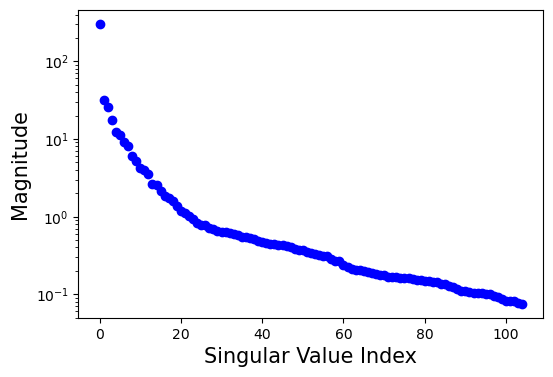

In [6]:
s = np.linalg.svd(vec_data)
fig, ax = plt.subplots(figsize=(6, 4))  # Width = 8, Height = 6 (inches)

# Plot the explained variance
ax.scatter(np.arange(s[1].shape[0]), s[1], marker='o', color='b')

# Add titles and labels
ax.set_xlabel(rf'Singular Value Index', fontsize=15)
ax.set_ylabel('Magnitude', fontsize=15)
ax.set_yscale('log')
# ax.legend(fontsize=12)
fig.savefig('mouse_svals.png', dpi=500, bbox_inches="tight")

In [7]:
data.shape

(60, 90, 105)

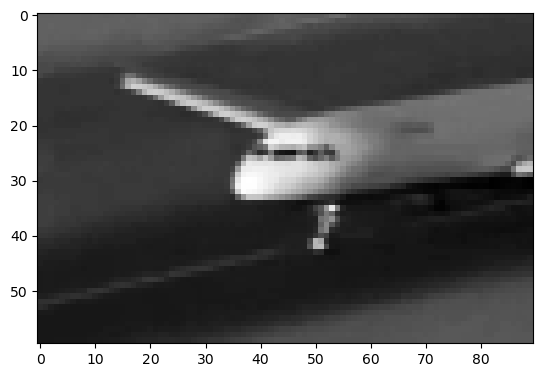

In [8]:
plt.imshow(data[:, :, 10], cmap='gray')

In [9]:
Xs = []

ell = 4 # Number of data samples per time index

st = 0
en = ell

for i in range(frames // ell):
    Xs.append(vec_data_norm[:, st:en])
    
    st += ell
    en += ell
    
T = len(Xs)

## Initialization

In [10]:
def spectral_init(Ys, frac_observed):
    """
    Performing spectral initialization for missing data case.
    """

    T = len(Ys)
    ell = Ys[0].shape[1]
    
    Xs_init = []

    for t in range(T):
        temp = []
        for i in range(ell):
            spect_mat = np.expand_dims( (1 / frac_observed)*Ys[t][:, i], axis=1 )
            temp.append( np.expand_dims(np.linalg.svd(spect_mat)[0][:, 0], axis=1) )

        Xs_init.append(np.concatenate(temp, axis=1))
        
    return Xs_init

In [11]:
def obj_func(Ys, Xs, forward, mask):
    """
    Function for computing objective function value.
    """

    if isinstance(Ys, list):
        Ys = np.concatenate(Ys, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(mask, list):
        mask = np.concatenate(mask, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]


def recovery(Xs, true_Xs):
    """
    Function for computing objective function value.
    """

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]

## Driver Code

In [14]:
FRAC_OBSERVED = 0.5
SIGMA = 0.01

NTRIALS = 1
NITERS = 5
RANK = 5



In [20]:
psnr_k_geodesic = np.zeros((NTRIALS, ))
ssim_k_geodesic = np.zeros((NTRIALS, ))
rmse_k_geodesic = np.zeros((NTRIALS, ))

all_ts = [
    # np.linspace(0.0, 1.0, T+0, endpoint=True), # [25:-25]
    # np.linspace(0.0, 1.0, T+30, endpoint=False)[15:-15],
    np.linspace(0.0, 1.0, T+50, endpoint=False)[25:-25],
]

all_geo_mm_est = []

for ts in all_ts:
    for trial in range( NTRIALS ):
        print('Trial Number: ', trial)

        # Generating data
        forward, transpose, masks = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,frac_observed=FRAC_OBSERVED)

        # Generate masked data
        Ys = []

        for i, Xi in enumerate(Xs):
            Ys.append( forward(Xi, masks[i]) + np.random.randn(*Xi.shape)*SIGMA )

        # Initializing
        Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)
        geo = init_geodesic(d=x*y, k=RANK, Xs=Xs_init, init="pca") # Initialize geodesic

        data_init = {
        "Xs":            Xs_init,
        "ts":            ts,
        "measurements":  Ys,
        "forward":       forward,
        "transpose":     transpose,
        "masks":         masks,
        }

        # Initial computations
        rmse_k_geodesic[trial, ] = compute_RMSE(data_init["Xs"], Xs)
        psnr_k_geodesic[trial, ] = compute_PSNR(data_init["Xs"], Xs)
        ssim_k_geodesic[trial, ] = compute_SSIM(data_init["Xs"], Xs)

        def callback(itr, geo, data):
            cur_rmse = compute_RMSE(data["Xs"], Xs)
            cur_psnr = compute_PSNR(data["Xs"], Xs)
            cur_ssim = compute_SSIM(data["Xs"], Xs)

            #if cur_rmse < rmse_k_geodesic[trial, ]:
            #if cur_psnr > psnr_k_geodesic[trial, ]:
            if True:
                rmse_k_geodesic[trial, ] = cur_rmse
                psnr_k_geodesic[trial, ] = cur_psnr
                ssim_k_geodesic[trial, ] = cur_ssim
            else:
                return True

            #if itr == NITERS - 1:
            print('(k-Geodesic) Iteration:', itr, 'PSNR:', psnr_k_geodesic[trial,], 'SSIM:', ssim_k_geodesic[trial, ], 'RMSE Error:', rmse_k_geodesic[trial, ])  

            return False

        estimator = GeodesicEstimator(rank=RANK)
        geo_mm_est = estimator.fit(
                        geo=geo,
                        data=data_init,
                        callback=callback,
                        niters=NITERS, 
                        lambda_fn=0.01,           
        )
        
        all_geo_mm_est.append(deepcopy(geo_mm_est))

Trial Number:  0
(k-Geodesic) Iteration: 0 PSNR: 18.216673863660564 SSIM: 0.36929807744415927 RMSE Error: 0.12312916940191612
(k-Geodesic) Iteration: 1 PSNR: 18.24369015561852 SSIM: 0.3745270037864223 RMSE Error: 0.12275201015739057
(k-Geodesic) Iteration: 2 PSNR: 18.281724634556888 SSIM: 0.3766035526556774 RMSE Error: 0.12221718668152305
(k-Geodesic) Iteration: 3 PSNR: 18.31937260402995 SSIM: 0.3786604952916939 RMSE Error: 0.12168963605959916
(k-Geodesic) Iteration: 4 PSNR: 18.357123949158765 SSIM: 0.38071539662343973 RMSE Error: 0.12116283019816879


In [21]:
X_geo_concats = [np.concatenate(geo_mm_est[1]["Xs"], axis=1) for geo_mm_est in all_geo_mm_est]
X_concat = np.concatenate(Xs, axis=1)

In [24]:
X_geo_concats

[array([[ 0.10020566,  0.11978847,  0.12964942, ...,  0.00143051,
          0.0472144 ,  0.05222567],
        [-0.00039023,  0.00030769, -0.00015553, ...,  0.00144399,
         -0.00039168, -0.00059194],
        [ 0.12394129,  0.00183439,  0.10652989, ...,  0.01833052,
          0.01802766,  0.00211013],
        ...,
        [ 0.07309378,  0.07202537,  0.00089739, ..., -0.00425803,
         -0.07605487, -0.07112752],
        [ 0.00123996,  0.00051443,  0.0569045 , ..., -0.05402874,
         -0.06872741,  0.00044264],
        [ 0.08129552,  0.07330821,  0.00049849, ..., -0.07778012,
          0.00037103, -0.05955924]])]

## Post-Processing

In [22]:
import matplotlib.pyplot as plt

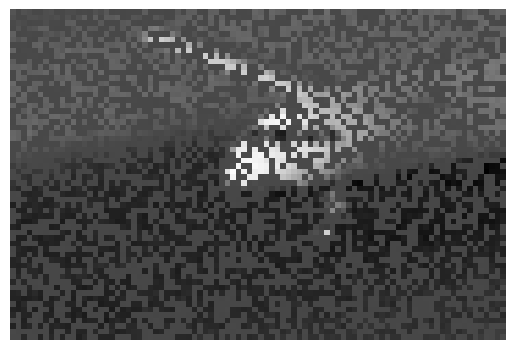

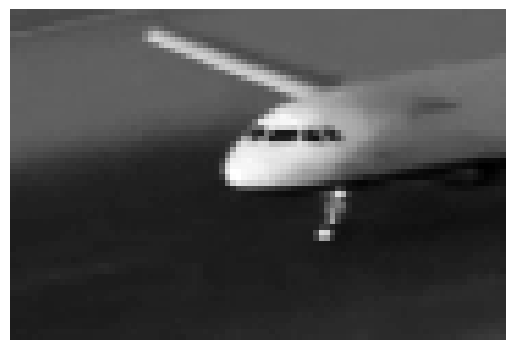

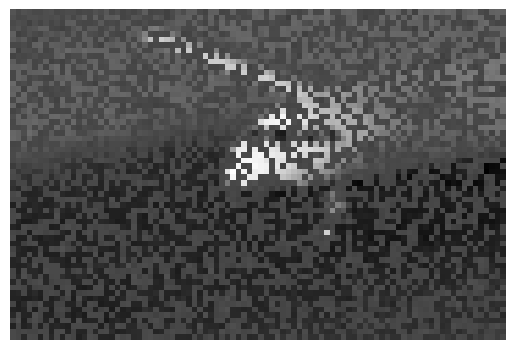

In [23]:
idx = 83
plt.imshow(np.reshape(X_geo_concats[0][:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/geo_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(X_concat[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/true_plane_frame{idx}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(np.concatenate(Ys, axis=1)[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/noisy_plane_frame{idx}.png', bbox_inches='tight', pad_inches=0)
plt.show()

In [ ]:
all_geo_psnr = []

for X_geo_concat in X_geo_concats:
    geo_psnrs = []

    for idx in range(X_geo_concat.shape[1]):
        geo_psnrs.append(psnr(normalize_np(X_geo_concat[:, idx]), normalize_np(X_concat[:, idx])))

    all_geo_psnr.append(geo_psnrs)

In [ ]:
plt.plot(all_geo_psnr[0])
plt.plot(all_geo_psnr[1])
plt.plot(all_geo_psnr[2])

## SVD Solution

In [ ]:
idx = 83

plt.imshow(np.reshape(X_geo_concat[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/geo_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(k_svd_soln[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/svdk_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(twok_svd_soln[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/svdtwok_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()